Chris McCarthy

DSC 540

Term Project: Milestone 5

Winter 2026

Merging the Data and Storing in a Database + Visualizing

The first step is bringing in all the datasets I've used in previous milestones and cleaning them here. That way, I can recreate the cleaned dataframes and proceed with joining them together.

In [1]:
#importing libraries I need for this

import requests
import pandas as pd

Milestone 2 Flat File CSV - Electric Vehicle Population

In [2]:
df_ev = pd.read_csv("data/Electric_Vehicle_Population_Data.csv")

df_ev.head()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 Census Tract
0,5YJ3E1EB9J,Kitsap,Bainbridge Island,WA,98110.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215.0,23.0,476462444,POINT (-122.521 47.62732),PUGET SOUND ENERGY INC,5.303509e+10
1,JN1AZ0CP2B,Kitsap,Port Orchard,WA,98367.0,2011,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,73.0,26.0,279030461,POINT (-122.70348 47.52028),PUGET SOUND ENERGY INC,5.303509e+10
2,JN1AZ0CP8B,King,Bothell,WA,98011.0,2011,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,73.0,1.0,232370001,POINT (-122.20563 47.76144),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303302e+10
3,1G1FY6S06L,Yakima,Selah,WA,98942.0,2020,CHEVROLET,BOLT EV,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,259.0,15.0,264646266,POINT (-120.53145 46.65405),PACIFICORP,5.307700e+10
4,KNDCM3LD3L,King,Seattle,WA,98133.0,2020,KIA,NIRO,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,26.0,32.0,154002691,POINT (-122.33364 47.73709),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303300e+10


Doing all 5 cleaning steps to prep (copy/pasting from milestone 2 notebook)

In [3]:
df_ev.columns = (
    df_ev.columns
      .str.lower()
      .str.replace(" ", "_")
      .str.replace("(", "", regex=False)
      .str.replace(")", "", regex=False)
)

df_ev.columns
df_ev.head()

,vin_1-10,county,city,state,postal_code,model_year,make,model,electric_vehicle_type,clean_alternative_fuel_vehicle_cafv_eligibility,electric_range,legislative_district,dol_vehicle_id,vehicle_location,electric_utility,2020_census_tract
0,5YJ3E1EB9J,Kitsap,Bainbridge Island,WA,98110.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215.0,23.0,476462444,POINT (-122.521 47.62732),PUGET SOUND ENERGY INC,5.303509e+10
1,JN1AZ0CP2B,Kitsap,Port Orchard,WA,98367.0,2011,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,73.0,26.0,279030461,POINT (-122.70348 47.52028),PUGET SOUND ENERGY INC,5.303509e+10
2,JN1AZ0CP8B,King,Bothell,WA,98011.0,2011,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,73.0,1.0,232370001,POINT (-122.20563 47.76144),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303302e+10
3,1G1FY6S06L,Yakima,Selah,WA,98942.0,2020,CHEVROLET,BOLT EV,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,259.0,15.0,264646266,POINT (-120.53145 46.65405),PACIFICORP,5.307700e+10
4,KNDCM3LD3L,King,Seattle,WA,98133.0,2020,KIA,NIRO,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,26.0,32.0,154002691,POINT (-122.33364 47.73709),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303300e+10


In [4]:
df_ev.isna().sum().sort_values(ascending=False)
#checking for missing values

legislative_district                               659
vehicle_location                                    88
county                                              10
city                                                10
postal_code                                         10
electric_utility                                    10
2020_census_tract                                   10
electric_range                                       7
vin_1-10                                             0
state                                                0
model_year                                           0
make                                                 0
model                                                0
electric_vehicle_type                                0
clean_alternative_fuel_vehicle_cafv_eligibility      0
dol_vehicle_id                                       0
dtype: int64

In [6]:
#counting rows before / after dropping
#I've decided county and city are most important for my analysis
#I'm dropping any rows that lack those

rows_before = df_ev.shape[0]

df_ev = df_ev.dropna(subset=["county", "city"])

rows_after = df_ev.shape[0]

print(f"Rows before drop: {rows_before}")
print(f"Rows after drop:  {rows_after}")
print(f"Rows removed:    {rows_before - rows_after}")

Rows before drop: 271113
Rows after drop:  271103
Rows removed:    10


In [7]:
df_ev[["county", "city"]].nunique()

county    246
city      870
dtype: int64

In [8]:
df_ev["county"].value_counts().head(10)

county
King         133815
Snohomish     33766
Pierce        22238
Clark         16694
Thurston       9911
Kitsap         9116
Spokane        7652
Whatcom        6664
Benton         3827
Skagit         3194
Name: count, dtype: int64

In [9]:
df_ev.dtypes

vin_1-10                                            object
county                                              object
city                                                object
state                                               object
postal_code                                        float64
model_year                                           int64
make                                                object
model                                               object
electric_vehicle_type                               object
clean_alternative_fuel_vehicle_cafv_eligibility     object
electric_range                                     float64
legislative_district                               float64
dol_vehicle_id                                       int64
vehicle_location                                    object
electric_utility                                    object
2020_census_tract                                  float64
dtype: object

In [10]:
df_ev["postal_code"] = (
    df_ev["postal_code"]
        .astype("Int64")   # handle NaN 
        .astype("string")  # convert to string
)

In [11]:
#checking df type now

df_ev.dtypes

vin_1-10                                                   object
county                                                     object
city                                                       object
state                                                      object
postal_code                                        string[python]
model_year                                                  int64
make                                                       object
model                                                      object
electric_vehicle_type                                      object
clean_alternative_fuel_vehicle_cafv_eligibility            object
electric_range                                            float64
legislative_district                                      float64
dol_vehicle_id                                              int64
vehicle_location                                           object
electric_utility                                           object
2020_censu

In [12]:
df_ev["electric_range"].describe()
#looking at statistical tests

count    271096.000000
mean         39.885428
std          78.764248
min           0.000000
25%           0.000000
50%           0.000000
75%          33.000000
max         337.000000
Name: electric_range, dtype: float64

In [13]:
#running IQR

Q1 = df_ev["electric_range"].quantile(0.25)
Q3 = df_ev["electric_range"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

lower_bound, upper_bound

(-49.5, 82.5)

In [14]:
# for now, I just want to flag outliers. creating a new column for them

df_ev["electric_range_outlier"] = (
    (df_ev["electric_range"] < lower_bound) |
    (df_ev["electric_range"] > upper_bound)
)

In [16]:
# showing the column

df_ev.loc[df_ev["electric_range_outlier"], "electric_range"].head(10)

0     215.0
3     259.0
7     215.0
8     249.0
11    220.0
13    150.0
14    200.0
16    238.0
17    291.0
19    215.0
Name: electric_range, dtype: float64

In [17]:
# total count

df_ev["electric_range_outlier"].value_counts()

electric_range_outlier
False    228613
True      42490
Name: count, dtype: int64

<Axes: >

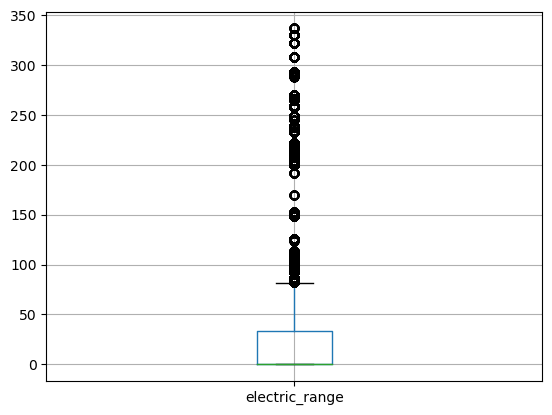

In [18]:
# boxplot for visual

df_ev.boxplot(column="electric_range")

In [19]:
# human readable dataset with transformations

df_ev.head(20)

,vin_1-10,county,city,state,postal_code,model_year,make,model,electric_vehicle_type,clean_alternative_fuel_vehicle_cafv_eligibility,electric_range,legislative_district,dol_vehicle_id,vehicle_location,electric_utility,2020_census_tract,electric_range_outlier
0,5YJ3E1EB9J,Kitsap,Bainbridge Island,WA,98110,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215.0,23.0,476462444,POINT (-122.521 47.62732),PUGET SOUND ENERGY INC,5.303509e+10,True
1,JN1AZ0CP2B,Kitsap,Port Orchard,WA,98367,2011,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,73.0,26.0,279030461,POINT (-122.70348 47.52028),PUGET SOUND ENERGY INC,5.303509e+10,False
2,JN1AZ0CP8B,King,Bothell,WA,98011,2011,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,73.0,1.0,232370001,POINT (-122.20563 47.76144),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303302e+10,False
3,1G1FY6S06L,Yakima,Selah,WA,98942,2020,CHEVROLET,BOLT EV,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,259.0,15.0,264646266,POINT (-120.53145 46.65405),PACIFICORP,5.307700e+10,True
4,KNDCM3LD3L,King,Seattle,WA,98133,2020,KIA,NIRO,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,26.0,32.0,154002691,POINT (-122.33364 47.73709),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303300e+10,False
5,KNDCS3LF9P,Thurston,Olympia,WA,98502,2023,KIA,NIRO,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,33.0,22.0,249788311,POINT (-122.92333 47.03779),PUGET SOUND ENERGY INC,5.306701e+10,False
6,WAUUPBFF9G,King,Seattle,WA,98103,2016,AUDI,A3,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,16.0,43.0,198988891,POINT (-122.35436 47.67596),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303300e+10,False
7,5YJ3E1EB9J,Thurston,Tumwater,WA,98512,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215.0,22.0,115875693,POINT (-123.04078 46.94792),PUGET SOUND ENERGY INC,5.306701e+10,True
8,5YJSA1E20J,Kitsap,Bremerton,WA,98337,2018,TESLA,MODEL S,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,249.0,26.0,261482455,POINT (-122.62749 47.565),PUGET SOUND ENERGY INC,5.303508e+10,True
9,1G1RD6S55H,Snohomish,Lynnwood,WA,98087,2017,CHEVROLET,VOLT,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,53.0,21.0,117693012,POINT (-122.27981 47.85727),PUGET SOUND ENERGY INC,5.306104e+10,False


Milestone 3 Website Data - https://afdc.energy.gov/laws/matrix?sort_by=tech - Govt matrix

Copy/pasting cleaning steps to prep for milestone

In [20]:
pd.set_option("display.max_columns", None)

url = "https://afdc.energy.gov/laws/matrix?sort_by=tech"

tables = pd.read_html(url)
tech_df = tables[0]

print("Tech/Fuel table shape:", tech_df.shape)
display(tech_df.head())
display(tech_df.tail())

Tech/Fuel table shape: (53, 16)


,Jurisdiction,Biodiesel,Ethanol,Natural Gas,Propane (LPG),Hydrogen Fuel Cells,EVs,PHEVs,HEVs,NEVs,Renewable Diesel,Aftermarket Conversions,Fuel Economy or Efficiency,Idle Reduction,Connected and Autonomous Vehicles,Other
0,Totals,334,305,420,315,440,1343,1142,134,59,37,74,80,100,43,98
1,Federal,41,35,42,35,61,86,75,14,5,9,8,15,8,4,16
2,Alabama,3,3,4,3,1,13,13,2,0,0,1,1,2,1,0
3,Alaska,1,2,1,2,1,8,7,0,1,0,1,1,1,0,0
4,Arizona,3,3,12,11,10,27,23,2,1,0,0,0,2,1,1


,Jurisdiction,Biodiesel,Ethanol,Natural Gas,Propane (LPG),Hydrogen Fuel Cells,EVs,PHEVs,HEVs,NEVs,Renewable Diesel,Aftermarket Conversions,Fuel Economy or Efficiency,Idle Reduction,Connected and Autonomous Vehicles,Other
48,Virginia,10,9,12,9,11,35,33,3,1,2,2,1,2,0,2
49,Washington,11,8,10,7,23,52,39,1,1,1,1,2,1,1,1
50,West Virginia,3,3,7,4,4,10,10,0,1,0,0,0,2,1,2
51,Wisconsin,12,9,9,9,6,24,23,3,1,0,0,0,2,0,1
52,Wyoming,3,4,6,4,1,8,7,0,0,2,0,0,0,0,0


In [21]:
tech_df.columns = (
    tech_df.columns
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("(", "", regex=False)
    .str.replace(")", "", regex=False)
)

display(tech_df.head())

,jurisdiction,biodiesel,ethanol,natural_gas,propane_lpg,hydrogen_fuel_cells,evs,phevs,hevs,nevs,renewable_diesel,aftermarket_conversions,fuel_economy_or_efficiency,idle_reduction,connected_and_autonomous_vehicles,other
0,Totals,334,305,420,315,440,1343,1142,134,59,37,74,80,100,43,98
1,Federal,41,35,42,35,61,86,75,14,5,9,8,15,8,4,16
2,Alabama,3,3,4,3,1,13,13,2,0,0,1,1,2,1,0
3,Alaska,1,2,1,2,1,8,7,0,1,0,1,1,1,0,0
4,Arizona,3,3,12,11,10,27,23,2,1,0,0,0,2,1,1


In [22]:
rows_before = tech_df.shape[0]

tech_df = tech_df[tech_df["jurisdiction"] != "Totals"]

rows_after = tech_df.shape[0]

print("Rows removed:", rows_before - rows_after)
display(tech_df.head())

Rows removed: 1


,jurisdiction,biodiesel,ethanol,natural_gas,propane_lpg,hydrogen_fuel_cells,evs,phevs,hevs,nevs,renewable_diesel,aftermarket_conversions,fuel_economy_or_efficiency,idle_reduction,connected_and_autonomous_vehicles,other
1,Federal,41,35,42,35,61,86,75,14,5,9,8,15,8,4,16
2,Alabama,3,3,4,3,1,13,13,2,0,0,1,1,2,1,0
3,Alaska,1,2,1,2,1,8,7,0,1,0,1,1,1,0,0
4,Arizona,3,3,12,11,10,27,23,2,1,0,0,0,2,1,1
5,Arkansas,4,3,6,6,2,11,8,3,0,2,2,0,1,2,2


In [23]:
rows_before = tech_df.shape[0]

tech_long = tech_df.melt(
    id_vars="jurisdiction",
    var_name="technology",
    value_name="count"
)

rows_after = tech_long.shape[0]

print("Rows before:", rows_before)
print("Rows after:", rows_after)
display(tech_long.head(15))

Rows before: 52
Rows after: 780


,jurisdiction,technology,count
0,Federal,biodiesel,41
1,Alabama,biodiesel,3
2,Alaska,biodiesel,1
3,Arizona,biodiesel,3
4,Arkansas,biodiesel,4
5,California,biodiesel,14
6,Colorado,biodiesel,7
7,Connecticut,biodiesel,2
8,Delaware,biodiesel,2
9,District of Columbia,biodiesel,2


In [24]:
rows_before = tech_long.shape[0]

tech_long = tech_long[tech_long["count"] > 0]

rows_after = tech_long.shape[0]

print("Rows removed:", rows_before - rows_after)
display(tech_long.head(15))

Rows removed: 132


,jurisdiction,technology,count
0,Federal,biodiesel,41
1,Alabama,biodiesel,3
2,Alaska,biodiesel,1
3,Arizona,biodiesel,3
4,Arkansas,biodiesel,4
5,California,biodiesel,14
6,Colorado,biodiesel,7
7,Connecticut,biodiesel,2
8,Delaware,biodiesel,2
9,District of Columbia,biodiesel,2


In [25]:
tech_long["technology"] = tech_long["technology"].str.replace("_", " ", regex=False).str.title()

display(tech_long.head(15))

,jurisdiction,technology,count
0,Federal,Biodiesel,41
1,Alabama,Biodiesel,3
2,Alaska,Biodiesel,1
3,Arizona,Biodiesel,3
4,Arkansas,Biodiesel,4
5,California,Biodiesel,14
6,Colorado,Biodiesel,7
7,Connecticut,Biodiesel,2
8,Delaware,Biodiesel,2
9,District of Columbia,Biodiesel,2


In [26]:
#running IQR

Q1 = tech_long["count"].quantile(0.25)
Q3 = tech_long["count"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 2.0
Q3: 8.0
IQR: 6.0
Lower Bound: -7.0
Upper Bound: 17.0


In [27]:
#flagging outliers

tech_long["outlier"] = (
    (tech_long["count"] < lower_bound) |
    (tech_long["count"] > upper_bound)
)

In [28]:
#counting and previewing outliers

outlier_count = tech_long["outlier"].sum()
print("Number of outliers detected:", outlier_count)

tech_long[tech_long["outlier"]].head(15)

Number of outliers detected: 66


,jurisdiction,technology,count,outlier
0,Federal,Biodiesel,41,True
52,Federal,Ethanol,35,True
104,Federal,Natural Gas,42,True
109,California,Natural Gas,28,True
156,Federal,Propane Lpg,35,True
208,Federal,Hydrogen Fuel Cells,61,True
213,California,Hydrogen Fuel Cells,63,True
230,Massachusetts,Hydrogen Fuel Cells,19,True
256,Washington,Hydrogen Fuel Cells,23,True
260,Federal,Evs,86,True


In [37]:
print("Final Cleaned Dataset Preview:")

df_fuel = tech_long
display(df_fuel.head(25))
display(df_fuel.tail(25))

Final Cleaned Dataset Preview:


,jurisdiction,technology,count,outlier
0,Federal,Biodiesel,41,True
1,Alabama,Biodiesel,3,False
2,Alaska,Biodiesel,1,False
3,Arizona,Biodiesel,3,False
4,Arkansas,Biodiesel,4,False
5,California,Biodiesel,14,False
6,Colorado,Biodiesel,7,False
7,Connecticut,Biodiesel,2,False
8,Delaware,Biodiesel,2,False
9,District of Columbia,Biodiesel,2,False


,jurisdiction,technology,count,outlier
746,Kentucky,Other,1,False
747,Louisiana,Other,1,False
748,Maine,Other,3,False
749,Maryland,Other,1,False
750,Massachusetts,Other,4,False
752,Minnesota,Other,1,False
753,Mississippi,Other,1,False
755,Montana,Other,1,False
756,Nebraska,Other,1,False
758,New Hampshire,Other,3,False


Milestone 4 - data prep and cleaning

In [30]:
#pulling from the API
url = "https://api.openchargemap.io/v3/poi/"

params = {
    "output": "json",
    "latitude": 47.6062,
    "longitude": -122.3321,
    "distance": 50,          #radius around Seattle; I chose 50 km to capture the greater seattle area
    "distanceunit": "KM",
    "maxresults": 100,
    "compact": True,
    "verbose": False
}

headers = {
    "User-Agent": "DSC540-class-project",
    "X-API-Key": "YOUR_OPENCHARGEMAP_API_KEY", #put your own Open Charge Map API key here
    "Accept": "application/json"
}

response = requests.get(url, params=params, headers=headers, timeout=30)
response.raise_for_status()

print("Status code:", response.status_code)

data = response.json()

df_charging = pd.json_normalize(data)

df_charging.head()
#preview the results to see columns

Status code: 200


,IsRecentlyVerified,DateLastVerified,ID,UUID,DataProviderID,DataProvidersReference,OperatorID,UsageTypeID,Connections,StatusTypeID,DateLastStatusUpdate,DataQualityLevel,DateCreated,SubmissionStatusTypeID,AddressInfo.ID,AddressInfo.Title,AddressInfo.AddressLine1,AddressInfo.Town,AddressInfo.StateOrProvince,AddressInfo.Postcode,AddressInfo.CountryID,AddressInfo.Latitude,AddressInfo.Longitude,AddressInfo.ContactTelephone1,AddressInfo.AccessComments,AddressInfo.RelatedURL,AddressInfo.Distance,AddressInfo.DistanceUnit,DatePlanned,OperatorsReference,NumberOfPoints,GeneralComments,UsageCost
0,True,2025-11-11T14:11:00Z,249621,FC842421-9F31-4702-85AC-D4A0B5B00C7F,2,181316,5.0,1,"[{'ID': 416416, 'ConnectionTypeID': 1, 'LevelI...",50.0,2025-11-11T14:11:00Z,3,2023-03-07T06:00:00Z,100,250005,INSIGNIA 953 225N,583 Battery St,Seattle,WA,98164,2,47.606111,-122.332163,888-758-4389,24 hours daily,https://www.chargepoint.com,0.010966,1,NaN,NaN,NaN,NaN,NaN
1,True,2025-11-11T14:11:00Z,249618,BC527C65-94D8-428F-8066-6D5E157E809A,2,164762,9.0,1,"[{'ID': 416413, 'ConnectionTypeID': 1, 'LevelI...",50.0,2025-11-11T14:11:00Z,3,2023-03-07T06:00:00Z,100,250002,VBG Seattle,901 Fifth Ave,Seattle,WA,98164,2,47.605780,-122.331858,888-998-2546,24 hours daily,https://blinkcharging.com,0.050102,1,NaN,NaN,NaN,NaN,NaN
2,True,2025-11-11T14:11:00Z,249625,01657D8E-9608-4D01-808B-1BB40B48C479,2,44153,NaN,1,"[{'ID': 416420, 'ConnectionTypeID': 1, 'LevelI...",50.0,2025-11-11T14:11:00Z,3,2023-03-07T06:00:00Z,100,250009,City of Seattle - Central Library,1000 4th Ave,Seattle,WA,98104,2,47.606684,-122.332664,206-386-4636,24 hours daily,,0.068442,1,NaN,NaN,NaN,NaN,NaN
3,False,2025-06-24T08:14:00Z,249616,4BCD4AD8-98D8-43B3-8A23-A675E53523FC,2,203325,9.0,1,"[{'ID': 416411, 'ConnectionTypeID': 1, 'LevelI...",50.0,2025-06-24T08:14:00Z,3,2023-03-07T06:00:00Z,100,250000,4th & Madison,925 4th Avenue,Seattle,WA,98104,2,47.605192,-122.332850,888-998-2546,24 hours daily,https://blinkcharging.com,0.125398,1,NaN,NaN,NaN,NaN,NaN
4,True,2025-11-11T14:11:00Z,249620,611F105D-873F-4482-B8AF-5F499BE33CC8,2,75391,5.0,1,"[{'ID': 416415, 'ConnectionTypeID': 1, 'LevelI...",50.0,2025-11-11T14:11:00Z,3,2023-03-07T06:00:00Z,100,250004,SAFECO PLAZA SAFECO PLAZA #1,1001 4th Ave Safeco Plaza,Seattle,WA,98154,2,47.606106,-122.333782,888-758-4389,24 hours daily,https://www.chargepoint.com,0.126532,1,NaN,NaN,NaN,NaN,NaN


In [31]:
#cleaning column names by replacing periods with underscores to be consistent with my other data sources
df_charging.columns = df_charging.columns.str.replace('.', '_')

df_charging.head()

,IsRecentlyVerified,DateLastVerified,ID,UUID,DataProviderID,DataProvidersReference,OperatorID,UsageTypeID,Connections,StatusTypeID,DateLastStatusUpdate,DataQualityLevel,DateCreated,SubmissionStatusTypeID,AddressInfo_ID,AddressInfo_Title,AddressInfo_AddressLine1,AddressInfo_Town,AddressInfo_StateOrProvince,AddressInfo_Postcode,AddressInfo_CountryID,AddressInfo_Latitude,AddressInfo_Longitude,AddressInfo_ContactTelephone1,AddressInfo_AccessComments,AddressInfo_RelatedURL,AddressInfo_Distance,AddressInfo_DistanceUnit,DatePlanned,OperatorsReference,NumberOfPoints,GeneralComments,UsageCost
0,True,2025-11-11T14:11:00Z,249621,FC842421-9F31-4702-85AC-D4A0B5B00C7F,2,181316,5.0,1,"[{'ID': 416416, 'ConnectionTypeID': 1, 'LevelI...",50.0,2025-11-11T14:11:00Z,3,2023-03-07T06:00:00Z,100,250005,INSIGNIA 953 225N,583 Battery St,Seattle,WA,98164,2,47.606111,-122.332163,888-758-4389,24 hours daily,https://www.chargepoint.com,0.010966,1,NaN,NaN,NaN,NaN,NaN
1,True,2025-11-11T14:11:00Z,249618,BC527C65-94D8-428F-8066-6D5E157E809A,2,164762,9.0,1,"[{'ID': 416413, 'ConnectionTypeID': 1, 'LevelI...",50.0,2025-11-11T14:11:00Z,3,2023-03-07T06:00:00Z,100,250002,VBG Seattle,901 Fifth Ave,Seattle,WA,98164,2,47.605780,-122.331858,888-998-2546,24 hours daily,https://blinkcharging.com,0.050102,1,NaN,NaN,NaN,NaN,NaN
2,True,2025-11-11T14:11:00Z,249625,01657D8E-9608-4D01-808B-1BB40B48C479,2,44153,NaN,1,"[{'ID': 416420, 'ConnectionTypeID': 1, 'LevelI...",50.0,2025-11-11T14:11:00Z,3,2023-03-07T06:00:00Z,100,250009,City of Seattle - Central Library,1000 4th Ave,Seattle,WA,98104,2,47.606684,-122.332664,206-386-4636,24 hours daily,,0.068442,1,NaN,NaN,NaN,NaN,NaN
3,False,2025-06-24T08:14:00Z,249616,4BCD4AD8-98D8-43B3-8A23-A675E53523FC,2,203325,9.0,1,"[{'ID': 416411, 'ConnectionTypeID': 1, 'LevelI...",50.0,2025-06-24T08:14:00Z,3,2023-03-07T06:00:00Z,100,250000,4th & Madison,925 4th Avenue,Seattle,WA,98104,2,47.605192,-122.332850,888-998-2546,24 hours daily,https://blinkcharging.com,0.125398,1,NaN,NaN,NaN,NaN,NaN
4,True,2025-11-11T14:11:00Z,249620,611F105D-873F-4482-B8AF-5F499BE33CC8,2,75391,5.0,1,"[{'ID': 416415, 'ConnectionTypeID': 1, 'LevelI...",50.0,2025-11-11T14:11:00Z,3,2023-03-07T06:00:00Z,100,250004,SAFECO PLAZA SAFECO PLAZA #1,1001 4th Ave Safeco Plaza,Seattle,WA,98154,2,47.606106,-122.333782,888-758-4389,24 hours daily,https://www.chargepoint.com,0.126532,1,NaN,NaN,NaN,NaN,NaN


In [32]:
#I've decided these columns are most relevant for analysis because they focus on location, usage cost and number of points

columns = [
    'AddressInfo_Title',
    'AddressInfo_AddressLine1',
    'AddressInfo_Town',
    'AddressInfo_StateOrProvince',
    'AddressInfo_Postcode',
    'AddressInfo_Latitude',
    'AddressInfo_Longitude',
    'AddressInfo_Distance',
    'NumberOfPoints',
    'UsageCost'
]

df_charging = df_charging[columns]

df_charging.head()

,AddressInfo_Title,AddressInfo_AddressLine1,AddressInfo_Town,AddressInfo_StateOrProvince,AddressInfo_Postcode,AddressInfo_Latitude,AddressInfo_Longitude,AddressInfo_Distance,NumberOfPoints,UsageCost
0,INSIGNIA 953 225N,583 Battery St,Seattle,WA,98164,47.606111,-122.332163,0.010966,NaN,NaN
1,VBG Seattle,901 Fifth Ave,Seattle,WA,98164,47.605780,-122.331858,0.050102,NaN,NaN
2,City of Seattle - Central Library,1000 4th Ave,Seattle,WA,98104,47.606684,-122.332664,0.068442,NaN,NaN
3,4th & Madison,925 4th Avenue,Seattle,WA,98104,47.605192,-122.332850,0.125398,NaN,NaN
4,SAFECO PLAZA SAFECO PLAZA #1,1001 4th Ave Safeco Plaza,Seattle,WA,98154,47.606106,-122.333782,0.126532,NaN,NaN


In [33]:
#I noticed NaNs in 'UsageCost' columns so I'm looking to do handling for those

df_charging['UsageCost'] = df_charging['UsageCost'].fillna("Unknown")

df_charging.isnull().sum()

AddressInfo_Title               0
AddressInfo_AddressLine1        0
AddressInfo_Town                0
AddressInfo_StateOrProvince     0
AddressInfo_Postcode            0
AddressInfo_Latitude            0
AddressInfo_Longitude           0
AddressInfo_Distance            0
NumberOfPoints                 89
UsageCost                       0
dtype: int64

In [34]:
#removing any duplicate records

df_charging = df_charging.drop_duplicates()

df_charging.shape

(97, 10)

In [35]:
#identifying outliers in NumberOfPoints using IQR

#NumberOfPoints is referencing the number of available charging connectors at a location

Q1 = df_charging['NumberOfPoints'].quantile(0.25)
Q3 = df_charging['NumberOfPoints'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_charging[(df_charging['NumberOfPoints'] < lower_bound) | (df_charging['NumberOfPoints'] > upper_bound)]

outliers

,AddressInfo_Title,AddressInfo_AddressLine1,AddressInfo_Town,AddressInfo_StateOrProvince,AddressInfo_Postcode,AddressInfo_Latitude,AddressInfo_Longitude,AddressInfo_Distance,NumberOfPoints,UsageCost
36,"Seattle, Wa - Union Street Supercharger",601 Union Street,Seattle,WA,98101,47.610024,-122.332078,0.425213,10.0,$0.25/kWh; other tariffs for older cars


In [36]:
print("Final cleaned dataset")

df_charging.head(20)

Final cleaned dataset


,AddressInfo_Title,AddressInfo_AddressLine1,AddressInfo_Town,AddressInfo_StateOrProvince,AddressInfo_Postcode,AddressInfo_Latitude,AddressInfo_Longitude,AddressInfo_Distance,NumberOfPoints,UsageCost
0,INSIGNIA 953 225N,583 Battery St,Seattle,WA,98164,47.606111,-122.332163,0.010966,NaN,Unknown
1,VBG Seattle,901 Fifth Ave,Seattle,WA,98164,47.605780,-122.331858,0.050102,NaN,Unknown
2,City of Seattle - Central Library,1000 4th Ave,Seattle,WA,98104,47.606684,-122.332664,0.068442,NaN,Unknown
3,4th & Madison,925 4th Avenue,Seattle,WA,98104,47.605192,-122.332850,0.125398,NaN,Unknown
4,SAFECO PLAZA SAFECO PLAZA #1,1001 4th Ave Safeco Plaza,Seattle,WA,98154,47.606106,-122.333782,0.126532,NaN,Unknown
5,800 FIFTH AVE STATION 2,800 5th Ave,Seattle,WA,98104,47.605599,-122.330626,0.129142,NaN,Unknown
6,SAFECO PLAZA SAFECO PLAZA #2,1001 4th Ave Safeco Plaza,Seattle,WA,98154,47.606218,-122.333842,0.130613,NaN,Unknown
7,Hotel Monaco Seattle,1101 Fourth Ave,Seattle,WA,98101,47.607141,-122.333917,0.171768,NaN,Unknown
8,800 Fifth Avenue Parking Garage,800 5th Ave,Seattle,WA,98104,47.605454,-122.330085,0.172293,NaN,Unknown
9,W Seattle,1112 4th Avenue,Seattle,WA,98101,47.607383,-122.333679,0.176965,NaN,Unknown


All previous milestone data has been properly cleaned and prepped for this final milestone

The dataframes are:

df_ev (CSV)

tech_df converted into tech_long changed to df_fuel (website)

df_charging (API)

MILESTONE 5 OFFICIAL START - SQL

In [38]:
import sqlite3

conn = sqlite3.connect("ev_project.db")

df_ev.to_sql("ev_population", conn, if_exists="replace", index=False)
df_fuel.to_sql("fuel_technology", conn, if_exists="replace", index=False)
df_charging.to_sql("charging_stations", conn, if_exists="replace", index=False)

97

In [39]:
pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

,name
0,ev_population
1,fuel_technology
2,charging_stations


In [40]:
#I realized when going to join datasets that my state column in df_ev and df_fuel were different. EV had abbreviations while Fuel had full spelling

state_map = {
    "AL": "Alabama",
    "AK": "Alaska",
    "AZ": "Arizona",
    "AR": "Arkansas",
    "CA": "California",
    "CO": "Colorado",
    "CT": "Connecticut",
    "DE": "Delaware",
    "FL": "Florida",
    "GA": "Georgia",
    "HI": "Hawaii",
    "ID": "Idaho",
    "IL": "Illinois",
    "IN": "Indiana",
    "IA": "Iowa",
    "KS": "Kansas",
    "KY": "Kentucky",
    "LA": "Louisiana",
    "ME": "Maine",
    "MD": "Maryland",
    "MA": "Massachusetts",
    "MI": "Michigan",
    "MN": "Minnesota",
    "MS": "Mississippi",
    "MO": "Missouri",
    "MT": "Montana",
    "NE": "Nebraska",
    "NV": "Nevada",
    "NH": "New Hampshire",
    "NJ": "New Jersey",
    "NM": "New Mexico",
    "NY": "New York",
    "NC": "North Carolina",
    "ND": "North Dakota",
    "OH": "Ohio",
    "OK": "Oklahoma",
    "OR": "Oregon",
    "PA": "Pennsylvania",
    "RI": "Rhode Island",
    "SC": "South Carolina",
    "SD": "South Dakota",
    "TN": "Tennessee",
    "TX": "Texas",
    "UT": "Utah",
    "VT": "Vermont",
    "VA": "Virginia",
    "WA": "Washington",
    "WV": "West Virginia",
    "WI": "Wisconsin",
    "WY": "Wyoming",
    "DC": "District of Columbia"
}

df_ev["state_full"] = df_ev["state"].map(state_map)

df_ev[["state", "state_full"]].head()

#created a state_full column for the join

,state,state_full
0,WA,Washington
1,WA,Washington
2,WA,Washington
3,WA,Washington
4,WA,Washington


In [41]:
#reloading my dataframes with the updated column

import sqlite3
import pandas as pd

conn = sqlite3.connect("ev_project.db")

df_ev.to_sql("ev_population", conn, if_exists="replace", index=False)
df_fuel.to_sql("fuel_technology", conn, if_exists="replace", index=False)
df_charging.to_sql("charging_stations", conn, if_exists="replace", index=False)

97

In [42]:
#merging all the datasets in SQL

query = """
SELECT
    ev.city,
    ev.state,
    ev.state_full,
    ev.ev_count,
    cs.station_count,
    cs.avg_points,
    ft.technology,
    ft.count AS technology_count
FROM
    (
        SELECT city, state, state_full, COUNT(*) AS ev_count
        FROM ev_population
        GROUP BY city, state, state_full
    ) ev
LEFT JOIN
    (
        SELECT
            AddressInfo_Town,
            AddressInfo_StateOrProvince,
            COUNT(*) AS station_count,
            AVG(NumberOfPoints) AS avg_points
        FROM charging_stations
        GROUP BY AddressInfo_Town, AddressInfo_StateOrProvince
    ) cs
ON ev.city = cs.AddressInfo_Town
AND ev.state = cs.AddressInfo_StateOrProvince
LEFT JOIN
    fuel_technology ft
ON ev.state_full = ft.jurisdiction
"""
merged_df = pd.read_sql_query(query, conn)

merged_df.head(20)

,city,state,state_full,ev_count,station_count,avg_points,technology,technology_count
0,Aberdeen,WA,Washington,263,NaN,NaN,Aftermarket Conversions,1.0
1,Aberdeen,WA,Washington,263,NaN,NaN,Biodiesel,11.0
2,Aberdeen,WA,Washington,263,NaN,NaN,Connected And Autonomous Vehicles,1.0
3,Aberdeen,WA,Washington,263,NaN,NaN,Ethanol,8.0
4,Aberdeen,WA,Washington,263,NaN,NaN,Evs,52.0
5,Aberdeen,WA,Washington,263,NaN,NaN,Fuel Economy Or Efficiency,2.0
6,Aberdeen,WA,Washington,263,NaN,NaN,Hevs,1.0
7,Aberdeen,WA,Washington,263,NaN,NaN,Hydrogen Fuel Cells,23.0
8,Aberdeen,WA,Washington,263,NaN,NaN,Idle Reduction,1.0
9,Aberdeen,WA,Washington,263,NaN,NaN,Natural Gas,10.0


In [43]:
#looking at merged_df again

print(merged_df.columns)
merged_df.head()

Index(['city', 'state', 'state_full', 'ev_count', 'station_count',
       'avg_points', 'technology', 'technology_count'],
      dtype='object')


,city,state,state_full,ev_count,station_count,avg_points,technology,technology_count
0,Aberdeen,WA,Washington,263,NaN,NaN,Aftermarket Conversions,1.0
1,Aberdeen,WA,Washington,263,NaN,NaN,Biodiesel,11.0
2,Aberdeen,WA,Washington,263,NaN,NaN,Connected And Autonomous Vehicles,1.0
3,Aberdeen,WA,Washington,263,NaN,NaN,Ethanol,8.0
4,Aberdeen,WA,Washington,263,NaN,NaN,Evs,52.0


I am pleased with the merged_df output because we are getting a look at relevant data points for analysis. We have city, state/state_full, ev_count, station_count, avg_points, technology and technology_count. There is both geolocation data, numeric hardware counts data, and technology/policy data. These are all meaningful angles of analysis that I can draw from to create visualizations of my milestone project.

Visualization 1 - EV counts by City (merged_df)

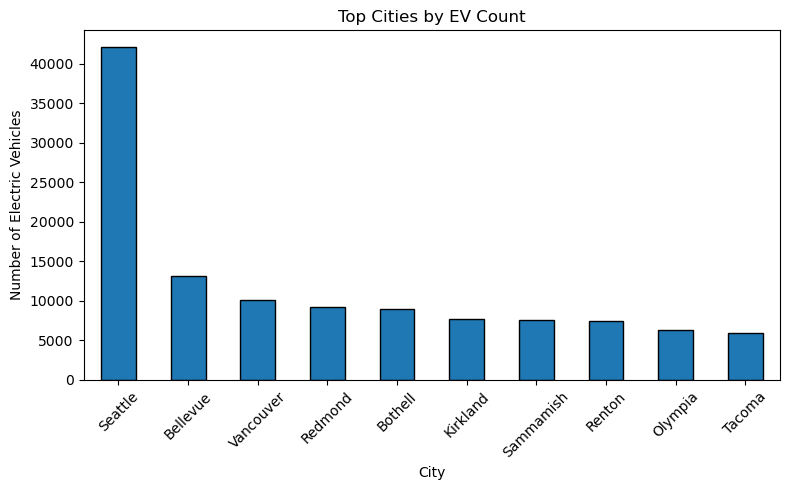

In [51]:
import matplotlib.pyplot as plt

top_cities = (
    merged_df.groupby("city")["ev_count"]
    .max()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(8, 5))

top_cities.plot(
    kind="bar",
    edgecolor="black",
    linewidth=1
)

plt.title("Top Cities by EV Count")
plt.xlabel("City")
plt.ylabel("Number of Electric Vehicles")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

This result is unsurprising given the density of Seattle as a metro area. I also find Bellevue's adoption of EVs expected because Bellevue is known as a hub for technology given its ties to Microsoft. I am surpised to see Vancouver's adoption of EVs being so high given its more suburban status. The rest of the cities are fairly even in their number of electric vehicles and I think overall, it's impressive to see widespread use of EVs.

Visualization 2 - Charging Points per Station in Seattle (df_charging)

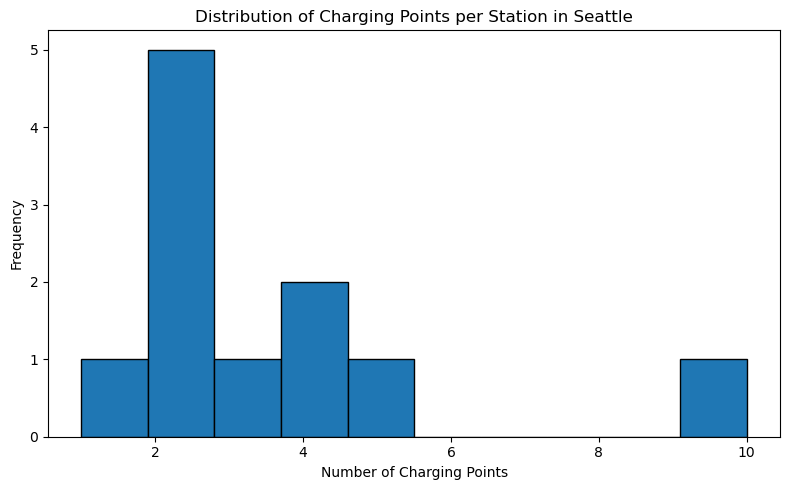

In [52]:
plt.figure(figsize=(8, 5))

df_charging["NumberOfPoints"].dropna().plot(
    kind="hist",
    bins=10,
    edgecolor="black",
    linewidth=1
)

plt.title("Distribution of Charging Points per Station in Seattle")
plt.xlabel("Number of Charging Points")
plt.ylabel("Frequency")
plt.tight_layout()

plt.show()

From the visual, the frequency of stations with 2 charging ports is the highest, followed by 4. One frustration I encountered with the API is the information it can return in one query is fairly limited in terms of geographic location. For instance, I wanted to look at charging point averages across all of WA state but the API requires lat/long to process information. This means each query can only return results limited to a specific city. I decided to go with Seattle since it's the hub of EVs in WA state but this is something I will learn from and look out for in future work.

Visualization 3 - EV Range by City in WA State (df_ev)

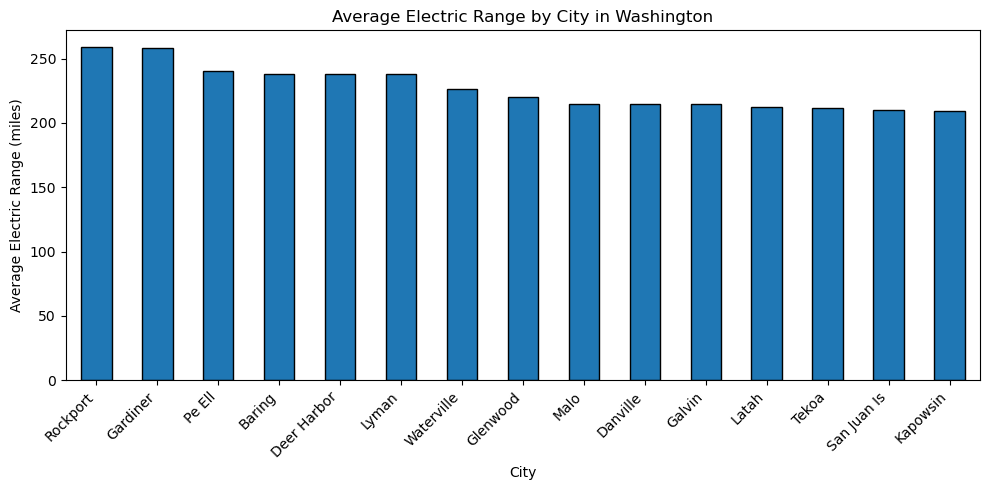

In [60]:
range_by_city = (
    df_ev[(df_ev["state"] == "WA") & (df_ev["electric_range"] > 0)] #excluding values of 0 to create better visual representation
    .groupby("city")["electric_range"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(10,5))

range_by_city.plot(
    kind="bar",
    edgecolor="black",
    linewidth=1
)

plt.title("Average Electric Range by City in Washington")
plt.xlabel("City")
plt.ylabel("Average Electric Range (miles)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

This is really cool to see. From the plot, average electric range in cities across Washington are fairly similar. This is important because it means the technology is available to places beyond urban centers like Seattle. Having EVs that perform well on average in many locations is a meaningful statistic when considering parity and ethical implications of EV development and access.

Visualization 4 - Alternative Fuel Technologies by Count (merged_df)

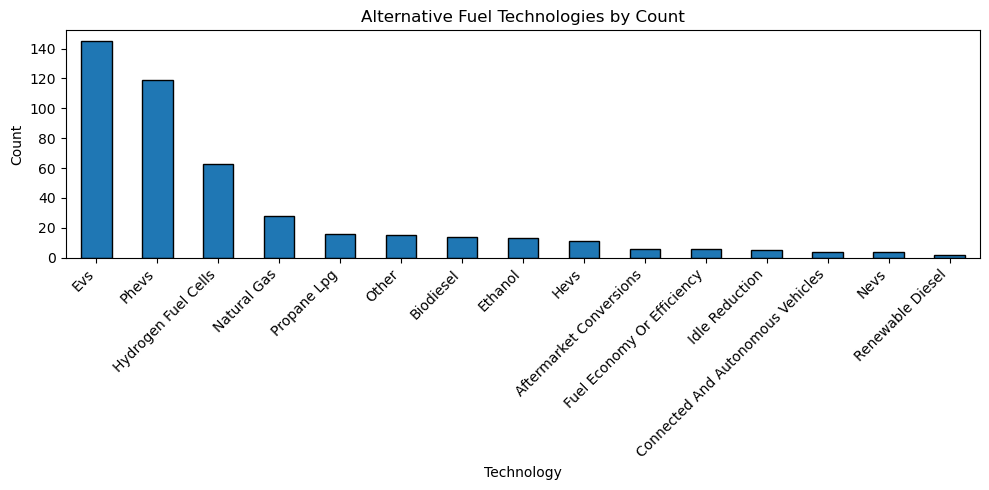

In [54]:
tech_totals = (
    merged_df.groupby("technology")["technology_count"]
    .max()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

tech_totals.plot(
    kind="bar",
    edgecolor="black",
    linewidth=1
)

plt.title("Alternative Fuel Technologies by Count")
plt.xlabel("Technology")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

This is an expected but fun result to look at. EVs are the dominant aleternative fuel technology and the plot reflects this. It's either EVs or PHEVs (Plug-in Hybrids). Hydrogen fuel cells is an interesting 3rd place and one I hadn't considered but after further research is a sensible alternative fuel method that is still related to the use of electricity (the fuel cell combines hydrogen and oxygen to produce water and release electricity). Natural gas and propane are expected 4th and 5th place rankings, rounding out the fuel technologies.

Visualization 5 - EV Adoption vs Average Electric Range by City (Washington) (df_ev)

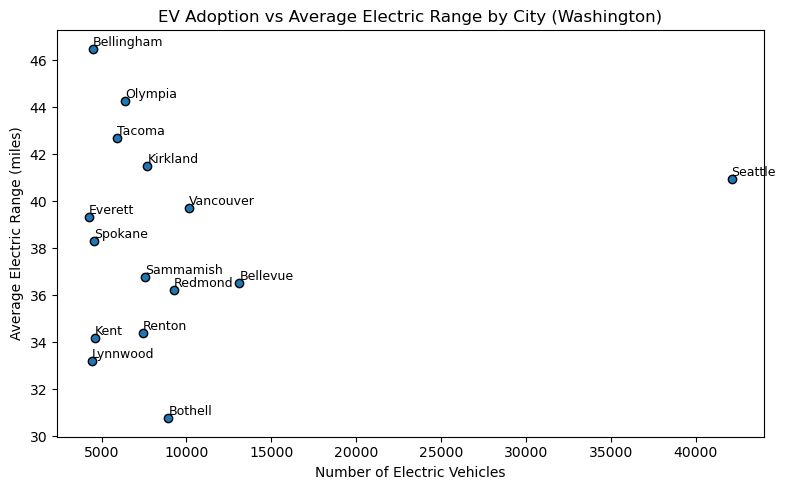

In [62]:
ev_stats = (
    df_ev[df_ev["state"] == "WA"]
    .groupby("city")
    .agg(
        ev_count=("city", "size"),
        avg_range=("electric_range", "mean")
    )
    .sort_values("ev_count", ascending=False)
    .head(15)
)

plt.figure(figsize=(8,5))

plt.scatter(
    ev_stats["ev_count"],
    ev_stats["avg_range"],
    edgecolor="black",
    linewidth=1
)

#city labels for better visual punch
for city, row in ev_stats.iterrows():
    plt.text(
        row["ev_count"],
        row["avg_range"],
        city,
        fontsize=9,
        ha="left",
        va="bottom"
    )

plt.title("EV Adoption vs Average Electric Range by City (Washington)")
plt.xlabel("Number of Electric Vehicles")
plt.ylabel("Average Electric Range (miles)")

plt.tight_layout()
plt.show()

I really like this visual comparison because it gives insights in multiple ways: overall # of EVs by city, average range of their EVs, visual representation of cities and their EV ranges, the spread/distribution, outliers and more. One thing to keep in mind is the range is lower than you'd expect because the data is accounting for all the 0 range values that are found in EV datasets (due to older models, errors, plug-in hybrids, etc). Very cool to see a relatively even clustering of total EV count and respectable range in miles.

Ethical Considerations

What changes were made to the data?

I made a number of transformations to the data. The primary focus of these changes was cleaning: removing duplicates, streamlining formatting such as underscores and capitalization, trimming column categories down to relevant ones for analysis, and so on. I also checked for missing values, and checked data types to make sure they were consistent.

Are there any legal or regulatory guidelines for your data or project topic?

The legal and regulatory guidelines for my project were determined by the government. All EV policy is pushed through by the federal and state government of the US and WA state.

What risks could be created based on the transformations done?

My transformations are low risk. Of course, there's always the chance that something gets removed and skipped over that could be supportive or insightful to my analysis, but the odds of that are low. This could come up when selecting which categories are important for analysis but ultimately, I have to make that choice.

Did you make any assumptions in cleaning/transforming the data?

My primary assumption was the data was sourced correctly by the government. In the case of the API, I assumed the data was gathered correctly by community efforts.

How was your data sourced/verified for credibility?

My data is verified by the government and available as an open-source csv. There is also data from the official government website and a community-driven API.

Was your data acquired in an ethical way?

I'm assuming the data was acquired ethically by the government and interested parties.

How would you mitigate any of the ethical implications you have identified?

I would immediately address any ethical implications identified. However, both my data wrangling and analysis has yielded fairly positive results in the ethics department. The availability of EVs in WA state seems reasonably distributed. If I were to continue researching the subject, I would drill down further (beyond region/city and charging stations) and start to look at average incomes of areas and if there is a relationship there.

Project Summary

I've enjoyed my subject of study for this project. The prevalance and increasing popularity of electric vehicles (EVs) gave weight to the purpose of my research. It's a modern and relevant field to study and I'm glad to have done so. I took three different data sources: a CSV, a website matrix, and an API. Each offered their own unique categories and data from which I could pull and generate tables, insights, and analysis.

Specifically, the first data source (CSV) gave me information about locations of EVs in WA state, and their electric driving range (among other categories). The second source (website) gave me information about alternative fuel technologies which is highly relevant to the exploration at hand. I formatted this matrix from wide to long for better analytical ease. The third and final source was the API that provided information on charging station locations in Seattle, along with the number of charging points available at those stations.

For this final project milestone, I copied over all of my original milestones and cleaned the data in this notebook so I could create three dataframes to merge in SQL. I focused on merging the data using geography (city and state), EV adoption rate (# of EVs), charging infrastructure info (ports available) and alternative fuel technology. This way, I could analyze all of these categories with and against each other to generate insights in the visuals.

Overall, I learned the importance of taking large datasets, cleaning them, and slowly working them down into more manageable slices. By doing this, I was better able to tackle categories of comparison that helped generate insights on the subject matter, which is EVs in WA state and their respective distribution by city. I learned that it's also important to take a step back and really think about what it is I'm trying to evaluate. It's easy to get lost in the magnitude of the data and the variety of categories. By focusing in, I became more effective at analyzing relevant data points in regards to EV adoption, average range, availability of charging ports, and alternative fuel technologies. Even now, I have ideas for further exploration that require taking these categories and digging into them even further. It's an exciting prospect and one that I appreciate as an aspiring data scientist.

Improvements

I've also reflected on improvements for next time. I think the main one would be really keeping my scope locked in to one area of study. In this case, just WA state. And to be even more specific, I would choose a number of specific cities to look at. In my first and fifth visualizations, I like the EV counts by city and how they compare. For the sake of scope, I would focus in on just those cities. This way, I could research further without worrying about the prospect of other states and the fed in general. I would also take only the information relevant to WA state from the government alternativel fuel technology website matrix. While the fourth visual for policies across the entirety of the US is very cool, I think it'd make more sense for this project to look at just WA state and see if there's correlations between the output and EV count. Regardless, I do think the inclusion of alternative fuel technologies is good. One final improvement I would make would be using the API to query data for each city that I've chosen. This way, I can create a bigger picture of charge port availability: one that goes beyond Seattle.

In conclusion, I'm fairly happy with how my project turned out and the major improvements I would make for next time would be narrowing my scope just a bit so I could dig further into WA state.